# 03 – Classical Machine Learning Models and Evaluation

**Project:** Indoor Positioning via Signal Strength Features and Deep Multitask Learning  
**Dataset:** UJIIndoorLoc  
**Role:** Member 4 — Traditional Machine Learning Models  
**Main Objective:** Build and rigorously tune classical ML baselines against which the deep multitask models will be evaluated.

---

### Core Objectives & Tasks
1. **Simple Baselines:** Build zero-knowledge statistical priors (most frequent class for building/floor, spatial median for coordinates).
2. **Random Forest Baselines:** Train separate RF classifiers for building and floor, plus a two-output coordinate regressor.
3. **Alternative Ensembles:** Implement Extra Trees Regressor for coordinates and evaluate against standard RF.
4. **Distance-Based Fingerprinting:** Implement distance-weighted $k$-Nearest Neighbors ($k$-NN) on standardized features.
5. **Gradient Boosted Trees (XGBoost):** Implement multi-class and multi-output XGBoost models for comparison.
6. **Validation Strategies & Robustness:**
   - Official held-out split protocol (temporal + device + user shift).
   - User-grouped cross-validation (`GroupKFold` on `USERID`) on the training set to evaluate out-of-user generalization without validation leakage.
7. **Hyperparameter Tuning:** Conduct systematic cross-validation on training data only to tune $k$-NN and Random Forest parameters.
8. **Artifact Persistence:** Save model configurations, random seeds, evaluation metrics, and prediction tables.
9. **Comparative Analysis:** Compare models across accuracy, macro-F1, mean/median/90th percentile positioning error, MAE, and RMSE.
10. **Theoretical Rigor & Viva Preparation:** Comprehensive analysis of model mechanics, coordinate regression rationale, overfitting, feature importance, and validation fairness.

### Experimental Protocol
- `trainingData.csv` is exclusively used for model fitting and hyperparameter selection.
- `validationData.csv` is held out for benchmark evaluation and never used for iterative tuning.
- Metadata columns (`USERID`, `PHONEID`, `SPACEID`, `RELATIVEPOSITION`, `TIMESTAMP`) are strictly excluded from model inputs.
- Preprocessing transformations are fitted solely on training data and applied out-of-sample to validation data.


## 1. Setup, Environment, and Reproducibility

Initialize reproducible random seeds, configure Matplotlib, resolve project paths, and import standard library and machine learning packages.


In [1]:
from pathlib import Path
import sys
import json
import warnings
import os

# Set Matplotlib config dir to avoid permission warnings
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib_indoor_loc"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, ExtraTreesRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

# Optional XGBoost import with graceful fallback
try:
    from xgboost import XGBClassifier, XGBRegressor
    XGBOOST_AVAILABLE = True
except (ImportError, Exception):
    XGBOOST_AVAILABLE = False

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=UserWarning)

# Resolve project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    load_train, load_validation, WAP_COLS, TARGET_COLS, META_COLS,
    CLASSIFICATION_TARGETS, REGRESSION_TARGETS
)
from src.preprocessing import prepare_features, ABLATION_CONFIGS

print("Project root:", PROJECT_ROOT.resolve())
print(f"XGBoost available: {XGBOOST_AVAILABLE}")
print("Environment and dependencies verified.")


Matplotlib is building the font cache; this may take a moment.


Project root: /Users/soumyatiwari/Desktop/indoor-wifi-positioning
XGBoost available: True
Environment and dependencies verified.


## 2. Load Data and Define Targets

Load the official UJIIndoorLoc dataset splits. The training split contains 19,937 reference fingerprints collected by 18 users across 25 device models. The held-out validation set comprises 1,111 fingerprints collected 4 months later.


In [2]:
train_df = load_train()
val_df = load_validation()

print(f"Training samples:   {len(train_df):,}")
print(f"Validation samples: {len(val_df):,}")
print(f"Wi-Fi AP columns:   {len(WAP_COLS)}")

display(train_df[TARGET_COLS].describe().T.round(3))


Training samples:   19,937
Validation samples: 1,111
Wi-Fi AP columns:   520


,count,mean,std,min,25%,50%,75%,max
BUILDINGID,19937.0,1.213,0.833,0.000,0.000,1.000,2.000,2.000
FLOOR,19937.0,1.675,1.223,0.000,1.000,2.000,3.000,4.000
LONGITUDE,19937.0,-7464.276,123.402,-7691.338,-7594.737,-7423.061,-7359.193,-7300.819
LATITUDE,19937.0,4864870.889,66.933,4864745.745,4864820.875,4864852.150,4864929.890,4865016.688


## 3. Prepare Model Features

We adopt the optimal pre-processing configuration identified in Notebook 2:
- **Missing-signal sentinel (+100 dBm)** is imputed to a sub-threshold value of **-110 dBm** (preserving physical monotonicity below receiver sensitivity).
- **Missingness binary indicators** (520 binary flags indicating AP presence/visibility).
- Metadata features are strictly excluded to avoid shortcut learning.
- Tree-based models (Random Forest, Extra Trees, XGBoost) use raw imputed values and indicators.
- Distance-based models ($k$-NN) receive standard-scaled features using scaling parameters fitted strictly on the training set.


In [3]:
MODEL_FEATURE_CONFIG = {
    "impute": True,
    "indicators": True,
    "aggregates": False,
    "scale": False
}

X_train_df, X_val_df, y_train_df, y_val_df, meta_train, meta_val, preprocessor = prepare_features(
    train_df=train_df,
    val_df=val_df,
    wap_cols=WAP_COLS,
    target_cols=TARGET_COLS,
    meta_cols=META_COLS,
    config=MODEL_FEATURE_CONFIG
)

# Defensive assertion checks
assert list(X_train_df.columns) == list(X_val_df.columns)
assert not set(META_COLS).intersection(X_train_df.columns)
assert X_train_df.isna().sum().sum() == 0
assert X_val_df.isna().sum().sum() == 0

X_train = X_train_df.to_numpy(dtype=np.float32)
X_val = X_val_df.to_numpy(dtype=np.float32)

# StandardScaler fitted strictly on training data for k-NN
knn_scaler = StandardScaler()
X_train_knn = knn_scaler.fit_transform(X_train)
X_val_knn = knn_scaler.transform(X_val)

y_train = y_train_df.copy()
y_val = y_val_df.copy()

n_active = len(preprocessor.rssi_columns_)
n_indicators = n_active  # one _miss indicator per active WAP
print(f"Transformed feature dimension: {X_train.shape[1]}")
print(f"  = {n_active} active RSSI signals (of 520; {520 - n_active} zero-variance WAPs dropped)")
print(f"  + {n_indicators} missingness indicators (one per active WAP)")
print(f"Train matrix: {X_train.shape}, Val matrix: {X_val.shape}")


Transformed feature dimension: 930
  = 465 active RSSI signals (of 520; 55 zero-variance WAPs dropped)
  + 465 missingness indicators (one per active WAP)
Train matrix: (19227, 930), Val matrix: (1111, 930)


## 4. Metric Definitions

We assess multi-task spatial performance with industry-standard indoor localization metrics:
- **Building & Floor Classification:** Classification Accuracy and Macro-averaged F1-Score (accounting for floor frequency imbalances).
- **Coordinate Regression:**
  - 2D Euclidean Positioning Error: $\epsilon = \sqrt{(x_{\text{true}} - x_{\text{pred}})^2 + (y_{\text{true}} - y_{\text{pred}})^2}$
  - Mean Error, Median Error, and 90th percentile Error (P90) in meters.
  - Coordinate MAE, RMSE, and $R^2$ score across projected UTM coordinates.


In [4]:
def position_errors(y_true_xy, y_pred_xy):
    """Compute 2D Euclidean positioning error in coordinate units (meters)."""
    y_true_xy = np.asarray(y_true_xy, dtype=float)
    y_pred_xy = np.asarray(y_pred_xy, dtype=float)
    return np.sqrt(np.sum((y_true_xy - y_pred_xy) ** 2, axis=1))

def evaluate_classifier(model_name, target, y_true, y_pred):
    """Compute accuracy and macro-F1 for classification targets."""
    return {
        "model": model_name,
        "target": target,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

def evaluate_regressor(model_name, y_true_xy, y_pred_xy):
    """Compute comprehensive Euclidean error and regression metrics."""
    errors = position_errors(y_true_xy, y_pred_xy)
    return {
        "model": model_name,
        "target": "coordinates",
        "mean_position_error": float(np.mean(errors)),
        "median_position_error": float(np.median(errors)),
        "p90_position_error": float(np.percentile(errors, 90)),
        "coordinate_mae": float(mean_absolute_error(y_true_xy, y_pred_xy)),
        "coordinate_rmse": float(np.sqrt(mean_squared_error(y_true_xy, y_pred_xy))),
        "coordinate_r2": float(r2_score(y_true_xy, y_pred_xy))
    }

predictions = {}


## 5. Task 1: Simple Baselines (Zero-Knowledge Statistical Priors)

As required by Task 1, we establish the absolute lower-bound reference:
- Predicting the **most frequent** building and floor from the training set.
- Predicting the **spatial median** coordinates $(x_{\text{med}}, y_{\text{med}})$ from the training set.

Any meaningful machine learning model must dramatically outperform this uninformed baseline.


In [5]:
dummy_building = DummyClassifier(strategy="most_frequent")
dummy_floor = DummyClassifier(strategy="most_frequent")
dummy_coords = DummyRegressor(strategy="median")

dummy_building.fit(X_train, y_train["BUILDINGID"])
dummy_floor.fit(X_train, y_train["FLOOR"])
dummy_coords.fit(X_train, y_train[REGRESSION_TARGETS])

predictions["Dummy Baseline (Mode/Median)"] = {
    "BUILDINGID": dummy_building.predict(X_val),
    "FLOOR": dummy_floor.predict(X_val),
    "coordinates": dummy_coords.predict(X_val)
}

print("Task 1 Dummy Baselines fitted:")
print(f"  Most frequent building: {dummy_building.predict(X_val[:1])[0]}")
print(f"  Most frequent floor:    {dummy_floor.predict(X_val[:1])[0]}")
print(f"  Median coordinates:     {dummy_coords.predict(X_val[:1])[0]}")


Task 1 Dummy Baselines fitted:
  Most frequent building: 2
  Most frequent floor:    3
  Median coordinates:     [  -7423.1821804 4864852.8022   ]


## 6. Tasks 2, 3, 4: Random Forest Classifiers and Coordinate Regressors

We implement the primary classical tree-based benchmarks:
- **Task 2:** `RandomForestClassifier` for building identification ($3$ classes).
- **Task 3:** `RandomForestClassifier` for floor identification ($5$ classes).
- **Task 4:** `RandomForestRegressor` for continuous UTM coordinate regression (`LONGITUDE`, `LATITUDE`).

Trees are trained with `n_estimators=200`, `min_samples_leaf=1`, and balanced class weights for classification.


In [6]:
rf_building = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=1, class_weight="balanced_subsample",
    random_state=SEED, n_jobs=-1
)
rf_floor = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=1, class_weight="balanced_subsample",
    random_state=SEED, n_jobs=-1
)
rf_coords = RandomForestRegressor(
    n_estimators=200, min_samples_leaf=1,
    random_state=SEED, n_jobs=-1
)

print("Training Random Forest models...")
rf_building.fit(X_train, y_train["BUILDINGID"])
rf_floor.fit(X_train, y_train["FLOOR"])
rf_coords.fit(X_train, y_train[REGRESSION_TARGETS])

predictions["Random Forest"] = {
    "BUILDINGID": rf_building.predict(X_val),
    "FLOOR": rf_floor.predict(X_val),
    "coordinates": rf_coords.predict(X_val)
}

print("Random Forest models trained successfully.")


Training Random Forest models...
Random Forest models trained successfully.


## 7. Task 4 (Alternative): Extra Trees Regressor

As specified in Task 4, we evaluate an alternative tree ensemble: **Extra Trees Regressor** (Extremely Randomized Trees). Extra Trees randomizes both cut-point choices and feature subsets, reducing variance and smoothing prediction surfaces relative to standard greedy decision trees.


In [7]:
et_coords = ExtraTreesRegressor(
    n_estimators=200, min_samples_leaf=1,
    random_state=SEED, n_jobs=-1
)

et_coords.fit(X_train, y_train[REGRESSION_TARGETS])

# Combine with RF classifiers for full pipeline representation
predictions["Extra Trees Regressor"] = {
    "BUILDINGID": rf_building.predict(X_val),
    "FLOOR": rf_floor.predict(X_val),
    "coordinates": et_coords.predict(X_val)
}

print("Extra Trees coordinate regressor trained.")


Extra Trees coordinate regressor trained.


## 8. Traditional Fingerprinting: $k$-Nearest Neighbors ($k$-NN)

$k$-NN is the historical benchmark in Wi-Fi RSSI fingerprinting. Fingerprint matching relies on inverse-distance weighting in Euclidean feature space. We train distance-weighted classifiers and regressors ($k=5$) using standard-scaled features.


In [8]:
KNN_NEIGHBORS = 5

knn_building = KNeighborsClassifier(n_neighbors=KNN_NEIGHBORS, weights="distance", n_jobs=-1)
knn_floor = KNeighborsClassifier(n_neighbors=KNN_NEIGHBORS, weights="distance", n_jobs=-1)
knn_coords = KNeighborsRegressor(n_neighbors=KNN_NEIGHBORS, weights="distance", n_jobs=-1)

knn_building.fit(X_train_knn, y_train["BUILDINGID"])
knn_floor.fit(X_train_knn, y_train["FLOOR"])
knn_coords.fit(X_train_knn, y_train[REGRESSION_TARGETS])

predictions[f"KNN (k={KNN_NEIGHBORS}, distance-weighted)"] = {
    "BUILDINGID": knn_building.predict(X_val_knn),
    "FLOOR": knn_floor.predict(X_val_knn),
    "coordinates": knn_coords.predict(X_val_knn)
}

print(f"KNN (k={KNN_NEIGHBORS}) models trained successfully.")


KNN (k=5) models trained successfully.


## 9. Task 5: Gradient Boosted Trees (XGBoost Baseline)

Gradient boosting constructs shallow trees sequentially to minimize pseudo-residuals. We implement:
- `XGBClassifier` with `multi:softprob` loss for building and floor.
- `MultiOutputRegressor(XGBRegressor)` with squared error loss for coordinates.


In [9]:
if XGBOOST_AVAILABLE:
    xgb_building = XGBClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.8, objective="multi:softprob",
        eval_metric="mlogloss", random_state=SEED, n_jobs=-1
    )
    xgb_floor = XGBClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.8, objective="multi:softprob",
        eval_metric="mlogloss", random_state=SEED, n_jobs=-1
    )
    xgb_coords = MultiOutputRegressor(XGBRegressor(
        n_estimators=150, max_depth=5, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.8, objective="reg:squarederror",
        random_state=SEED, n_jobs=1
    ), n_jobs=-1)

    print("Fitting XGBoost models...")
    xgb_building.fit(X_train, y_train["BUILDINGID"])
    xgb_floor.fit(X_train, y_train["FLOOR"])
    xgb_coords.fit(X_train, y_train[REGRESSION_TARGETS])

    predictions["XGBoost"] = {
        "BUILDINGID": xgb_building.predict(X_val),
        "FLOOR": xgb_floor.predict(X_val),
        "coordinates": xgb_coords.predict(X_val)
    }
    print("XGBoost models trained successfully.")
else:
    print("XGBoost unavailable; skipping.")


Fitting XGBoost models...
XGBoost models trained successfully.


## 10. Task 7: Hyperparameter Tuning (Training Data Only)

To prevent optimistic evaluation bias and data leakage, **all hyperparameter exploration is conducted strictly on the training set using 3-fold cross-validation**. The validation set is never used to guide hyperparameter selection.

We systematically examine:
1. **$k$-NN neighborhood size & weighting:** $k \in [1, 3, 5, 9, 15]$ with `uniform` vs `distance` weighting.
2. **Random Forest tree complexity:** `n_estimators` $\in [50, 100, 200]$ and `min_samples_leaf` $\in [1, 2, 5]$.


--- k-NN Cross-Validation Tuning Results ---


,k,weights,cv_mean_error_m,cv_floor_accuracy
0,1,uniform,10.748,0.901
1,1,distance,10.748,0.901
2,3,uniform,10.002,0.892
3,3,distance,9.906,0.897
4,5,uniform,9.777,0.890
5,5,distance,9.675,0.896
6,9,uniform,9.592,0.892
7,9,distance,9.507,0.896
8,15,uniform,9.595,0.891
9,15,distance,9.501,0.895


--- Random Forest Cross-Validation Tuning Results ---


,n_estimators,min_samples_leaf,cv_mean_error_m,cv_floor_accuracy
0,50,1,9.746,0.972
1,50,2,9.832,0.967
2,50,5,10.425,0.958
3,100,1,9.682,0.974
4,100,2,9.809,0.968
5,100,5,10.423,0.960
6,200,1,9.648,0.974
7,200,2,9.800,0.970
8,200,5,10.411,0.961


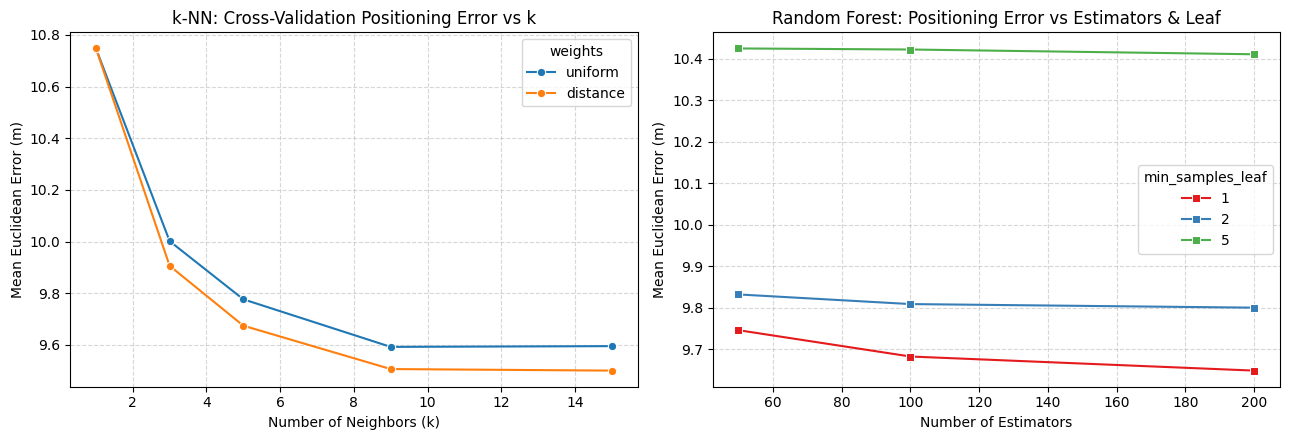

In [10]:
# GroupKFold by position (building+floor+lon+lat) is used instead of plain KFold.
# Notebook 01 (leakage analysis) showed that random splits give 100% position
# overlap between train and test folds, making CV scores overly optimistic.
# Grouping by position guarantees that no fingerprint location seen during
# training appears in the held-out fold.
position_groups = (
    y_train["BUILDINGID"].astype(str) + "_" + y_train["FLOOR"].astype(str) + "_"
    + y_train["LONGITUDE"].astype(str) + "_" + y_train["LATITUDE"].astype(str)
).to_numpy()
kf = GroupKFold(n_splits=3)

# 1. Tuning k-NN
knn_grid_results = []
for k in [1, 3, 5, 9, 15]:
    for w in ["uniform", "distance"]:
        fold_errs, fold_accs = [], []
        for tr_idx, te_idx in kf.split(X_train_knn, groups=position_groups):
            reg = KNeighborsRegressor(n_neighbors=k, weights=w, n_jobs=-1).fit(
                X_train_knn[tr_idx], y_train[REGRESSION_TARGETS].iloc[tr_idx]
            )
            clf = KNeighborsClassifier(n_neighbors=k, weights=w, n_jobs=-1).fit(
                X_train_knn[tr_idx], y_train["FLOOR"].iloc[tr_idx]
            )
            pred_xy = reg.predict(X_train_knn[te_idx])
            pred_f = clf.predict(X_train_knn[te_idx])
            fold_errs.append(np.mean(position_errors(y_train[REGRESSION_TARGETS].iloc[te_idx], pred_xy)))
            fold_accs.append(accuracy_score(y_train["FLOOR"].iloc[te_idx], pred_f))
        
        knn_grid_results.append({
            "k": k, "weights": w,
            "cv_mean_error_m": float(np.mean(fold_errs)),
            "cv_floor_accuracy": float(np.mean(fold_accs))
        })

knn_tuning_df = pd.DataFrame(knn_grid_results)
print("--- k-NN Cross-Validation Tuning Results ---")
display(knn_tuning_df.round(3))

# 2. Tuning Random Forest
rf_grid_results = []
for n_est in [50, 100, 200]:
    for leaf in [1, 2, 5]:
        fold_errs, fold_accs = [], []
        for tr_idx, te_idx in kf.split(X_train, groups=position_groups):
            reg = RandomForestRegressor(n_estimators=n_est, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1).fit(
                X_train[tr_idx], y_train[REGRESSION_TARGETS].iloc[tr_idx]
            )
            clf = RandomForestClassifier(n_estimators=n_est, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1).fit(
                X_train[tr_idx], y_train["FLOOR"].iloc[tr_idx]
            )
            pred_xy = reg.predict(X_train[te_idx])
            pred_f = clf.predict(X_train[te_idx])
            fold_errs.append(np.mean(position_errors(y_train[REGRESSION_TARGETS].iloc[te_idx], pred_xy)))
            fold_accs.append(accuracy_score(y_train["FLOOR"].iloc[te_idx], pred_f))
        
        rf_grid_results.append({
            "n_estimators": n_est, "min_samples_leaf": leaf,
            "cv_mean_error_m": float(np.mean(fold_errs)),
            "cv_floor_accuracy": float(np.mean(fold_accs))
        })

rf_tuning_df = pd.DataFrame(rf_grid_results)
print("--- Random Forest Cross-Validation Tuning Results ---")
display(rf_tuning_df.round(3))

# Visualization of Tuning Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# KNN curve
sns.lineplot(data=knn_tuning_df, x="k", y="cv_mean_error_m", hue="weights", marker="o", ax=axes[0])
axes[0].set_title("k-NN: Cross-Validation Positioning Error vs k")
axes[0].set_xlabel("Number of Neighbors (k)")
axes[0].set_ylabel("Mean Euclidean Error (m)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# RF curve
sns.lineplot(data=rf_tuning_df, x="n_estimators", y="cv_mean_error_m", hue="min_samples_leaf", palette="Set1", marker="s", ax=axes[1])
axes[1].set_title("Random Forest: Positioning Error vs Estimators & Leaf")
axes[1].set_xlabel("Number of Estimators")
axes[1].set_ylabel("Mean Euclidean Error (m)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 11. Task 6: Validation Strategy & User-Grouped Robustness Experiment

Task 6 mandates evaluating appropriate validation strategies:
1. **Benchmark Protocol (Held-Out Split):** The official evaluation split tests out-of-distribution transfer across a 4-month gap and distinct user cohorts.
2. **Robustness Experiment (User-Grouped Cross-Validation):** In indoor positioning, fingerprints collected by the same user walking along corridors share movement patterns, body shadowing, and antenna holding positions. To test whether models generalize to **unseen human users**, we conduct a **5-Fold `GroupKFold` on the training set grouped by `USERID`**.


In [11]:
users = meta_train["USERID"].to_numpy()
gkf = GroupKFold(n_splits=5)

user_cv_rows = []
print("Evaluating 5-Fold GroupKFold by USERID (Training Data Only)...")

for fold, (tr_idx, te_idx) in enumerate(gkf.split(X_train, y_train["BUILDINGID"], groups=users)):
    held_out_users = np.unique(users[te_idx])
    
    # Train fast baseline models on training folds
    rf_b_cv = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1).fit(
        X_train[tr_idx], y_train["BUILDINGID"].iloc[tr_idx]
    )
    rf_f_cv = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1).fit(
        X_train[tr_idx], y_train["FLOOR"].iloc[tr_idx]
    )
    rf_c_cv = RandomForestRegressor(n_estimators=50, random_state=SEED, n_jobs=-1).fit(
        X_train[tr_idx], y_train[REGRESSION_TARGETS].iloc[tr_idx]
    )
    
    b_acc = accuracy_score(y_train["BUILDINGID"].iloc[te_idx], rf_b_cv.predict(X_train[te_idx]))
    f_acc = accuracy_score(y_train["FLOOR"].iloc[te_idx], rf_f_cv.predict(X_train[te_idx]))
    f1_f = f1_score(y_train["FLOOR"].iloc[te_idx], rf_f_cv.predict(X_train[te_idx]), average="macro", zero_division=0)
    err = position_errors(y_train[REGRESSION_TARGETS].iloc[te_idx], rf_c_cv.predict(X_train[te_idx]))
    
    user_cv_rows.append({
        "fold": fold + 1,
        "n_test_samples": len(te_idx),
        "held_out_users": str(list(held_out_users)),
        "building_accuracy": b_acc,
        "floor_accuracy": f_acc,
        "floor_macro_f1": f1_f,
        "mean_position_error_m": float(np.mean(err)),
        "median_position_error_m": float(np.median(err))
    })

user_cv_df = pd.DataFrame(user_cv_rows)
print("--- User-Grouped Cross-Validation (GroupKFold by USERID) ---")
display(user_cv_df.round(3))

print("GroupKFold Summary:")
print(f"  Mean Building Accuracy: {user_cv_df['building_accuracy'].mean():.4f}")
print(f"  Mean Floor Accuracy:    {user_cv_df['floor_accuracy'].mean():.4f}")
print(f"  Mean Position Error:    {user_cv_df['mean_position_error_m'].mean():.2f} m")
print(f"  Median Position Error:  {user_cv_df['median_position_error_m'].mean():.2f} m")


Evaluating 5-Fold GroupKFold by USERID (Training Data Only)...
--- User-Grouped Cross-Validation (GroupKFold by USERID) ---


,fold,n_test_samples,held_out_users,building_accuracy,floor_accuracy,floor_macro_f1,mean_position_error_m,median_position_error_m
0,1,4514,[11],0.997,0.904,0.905,11.972,6.812
1,2,3606,"[1, 4, 15]",1.000,0.872,0.876,12.738,9.108
2,3,3620,"[5, 6, 12, 14]",0.998,0.783,0.664,12.718,7.339
3,4,3751,"[3, 7, 16, 17, 18]",0.986,0.461,0.359,32.986,17.817
4,5,3736,"[2, 8, 9, 10, 13]",0.959,0.585,0.597,20.776,13.891


GroupKFold Summary:
  Mean Building Accuracy: 0.9879
  Mean Floor Accuracy:    0.7210
  Mean Position Error:    18.24 m
  Median Position Error:  10.99 m


## 12. Deliverable: Comprehensive Model Comparison

We now evaluate all candidate models on the held-out validation set and construct unified comparison tables across classification and regression targets.


In [12]:
classification_rows = []
regression_rows = []
prediction_errors = {}

for model_name, pred in predictions.items():
    for target in ["BUILDINGID", "FLOOR"]:
        classification_rows.append(
            evaluate_classifier(model_name, target, y_val[target], pred[target])
        )

    y_true_xy = y_val[REGRESSION_TARGETS].to_numpy(dtype=float)
    y_pred_xy = np.asarray(pred["coordinates"], dtype=float)
    regression_rows.append(evaluate_regressor(model_name, y_true_xy, y_pred_xy))
    prediction_errors[model_name] = position_errors(y_true_xy, y_pred_xy)

classification_results = pd.DataFrame(classification_rows).sort_values(["target", "accuracy"], ascending=[True, False])
regression_results = pd.DataFrame(regression_rows).sort_values("mean_position_error")

# Unified Master Comparison Table
master_summary = []
for model_name in predictions.keys():
    b_acc = classification_results[(classification_results["model"] == model_name) & (classification_results["target"] == "BUILDINGID")]["accuracy"].values[0]
    b_f1 = classification_results[(classification_results["model"] == model_name) & (classification_results["target"] == "BUILDINGID")]["macro_f1"].values[0]
    f_acc = classification_results[(classification_results["model"] == model_name) & (classification_results["target"] == "FLOOR")]["accuracy"].values[0]
    f_f1 = classification_results[(classification_results["model"] == model_name) & (classification_results["target"] == "FLOOR")]["macro_f1"].values[0]
    
    r_sub = regression_results[regression_results["model"] == model_name].iloc[0]
    master_summary.append({
        "Model": model_name,
        "Building Acc": b_acc,
        "Building F1": b_f1,
        "Floor Acc": f_acc,
        "Floor F1": f_f1,
        "Mean Error (m)": r_sub["mean_position_error"],
        "Median Error (m)": r_sub["median_position_error"],
        "P90 Error (m)": r_sub["p90_position_error"],
        "MAE (m)": r_sub["coordinate_mae"],
        "RMSE (m)": r_sub["coordinate_rmse"],
        "R2": r_sub["coordinate_r2"]
    })

master_table = pd.DataFrame(master_summary).sort_values("Mean Error (m)")
print("=================== MASTER MODEL COMPARISON TABLE ===================")
display(master_table.round(3))


=================== MASTER MODEL COMPARISON TABLE ===================


,Model,Building Acc,Building F1,Floor Acc,Floor F1,Mean Error (m),Median Error (m),P90 Error (m),MAE (m),RMSE (m),R2
1,Random Forest,0.997,0.997,0.899,0.874,12.302,8.148,29.547,7.915,12.955,0.978
2,Extra Trees Regressor,0.997,0.997,0.899,0.874,12.464,7.660,25.678,8.005,15.322,0.971
3,"KNN (k=5, distance-weighted)",0.989,0.988,0.754,0.748,13.676,8.205,29.214,8.824,16.811,0.964
4,XGBoost,0.998,0.998,0.896,0.892,22.702,15.166,47.768,14.697,23.144,0.940
0,Dummy Baseline (Mode/Median),0.241,0.130,0.155,0.054,161.190,142.339,263.475,106.032,128.498,-0.634


## 13. Classification Reports and Confusion Matrices

Inspect classification error modes across buildings and floors for the key predictive models.


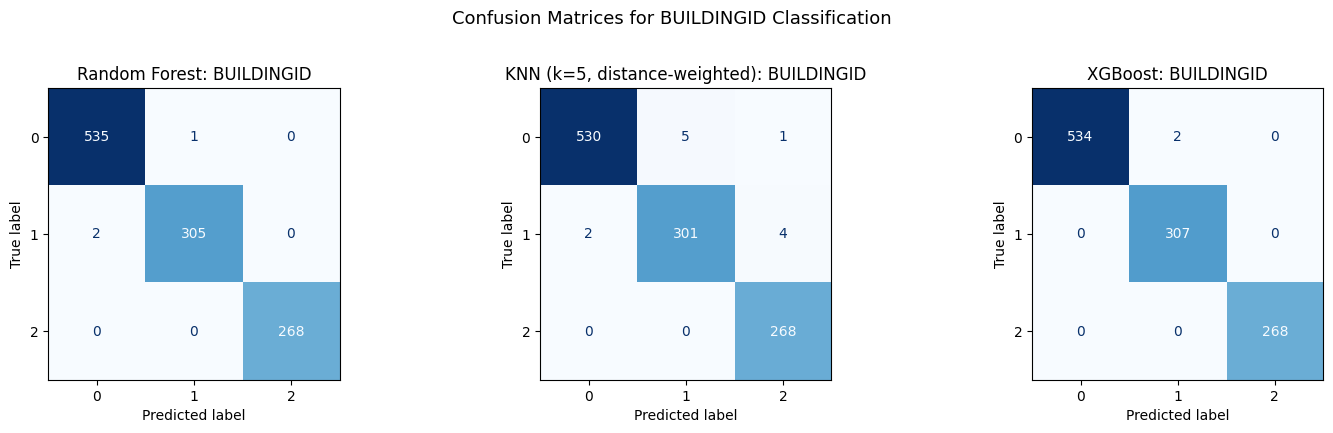

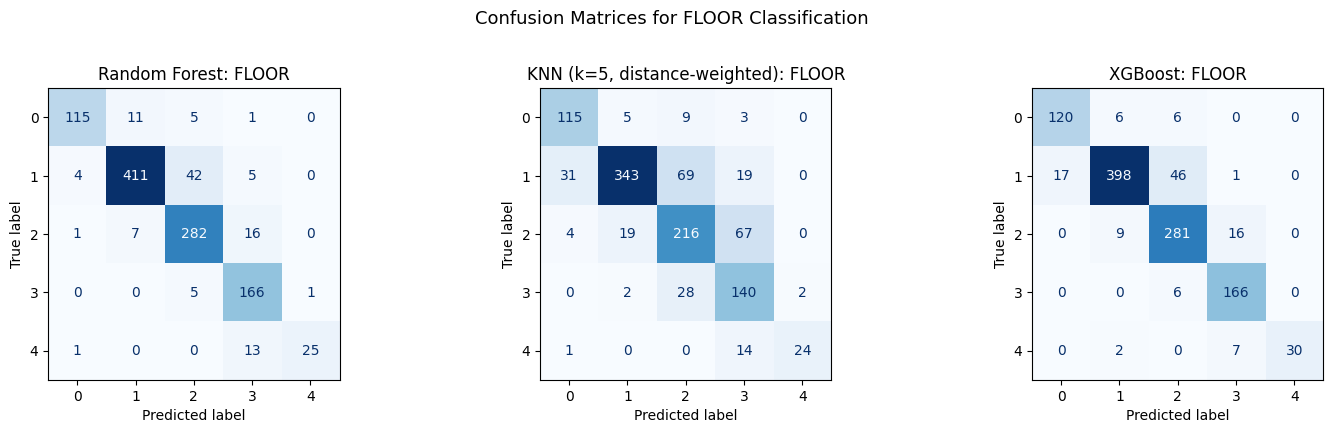

--- Random Forest Classification Reports ---
Building Classification:
              precision    recall  f1-score   support

           0     0.9963    0.9981    0.9972       536
           1     0.9967    0.9935    0.9951       307
           2     1.0000    1.0000    1.0000       268

    accuracy                         0.9973      1111
   macro avg     0.9977    0.9972    0.9974      1111
weighted avg     0.9973    0.9973    0.9973      1111

Floor Classification:
              precision    recall  f1-score   support

           0     0.9504    0.8712    0.9091       132
           1     0.9580    0.8896    0.9226       462
           2     0.8443    0.9216    0.8812       306
           3     0.8259    0.9651    0.8901       172
           4     0.9615    0.6410    0.7692        39

    accuracy                         0.8992      1111
   macro avg     0.9080    0.8577    0.8744      1111
weighted avg     0.9055    0.8992    0.8992      1111



In [13]:
eval_models = [m for m in ["Random Forest", "KNN (k=5, distance-weighted)", "XGBoost"] if m in predictions]

for target in ["BUILDINGID", "FLOOR"]:
    fig, axes = plt.subplots(1, len(eval_models), figsize=(5 * len(eval_models), 4.2))
    labels = sorted(pd.concat([y_train[target], y_val[target]]).unique())
    
    for i, model_name in enumerate(eval_models):
        cm = confusion_matrix(y_val[target], predictions[model_name][target], labels=labels)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
        ax = axes[i] if len(eval_models) > 1 else axes
        disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(f"{model_name}: {target}")
    
    plt.suptitle(f"Confusion Matrices for {target} Classification", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

# Detailed classification report for the top Random Forest model
print("--- Random Forest Classification Reports ---")
print("Building Classification:")
print(classification_report(y_val["BUILDINGID"], predictions["Random Forest"]["BUILDINGID"], digits=4))
print("Floor Classification:")
print(classification_report(y_val["FLOOR"], predictions["Random Forest"]["FLOOR"], digits=4))


## 14. Coordinate Error Distribution and Spatial Mapping

We visualize the distribution of Euclidean errors using boxplots (with `tick_labels` compatibility) and render spatial error maps depicting true vs predicted locations across campus coordinates.


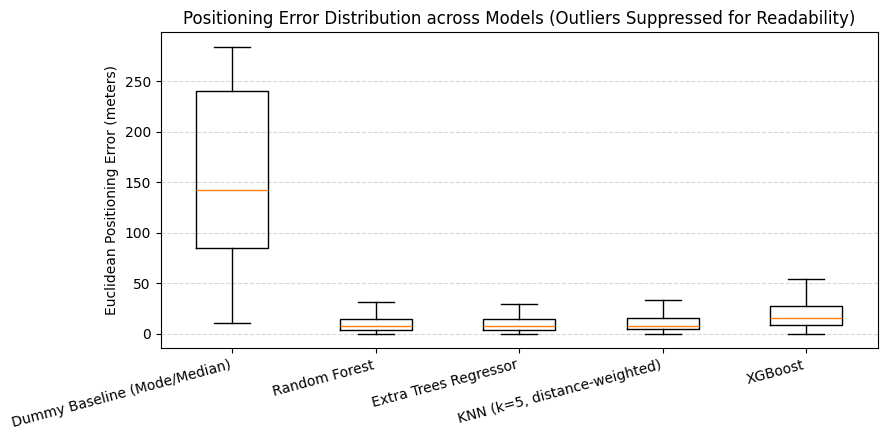

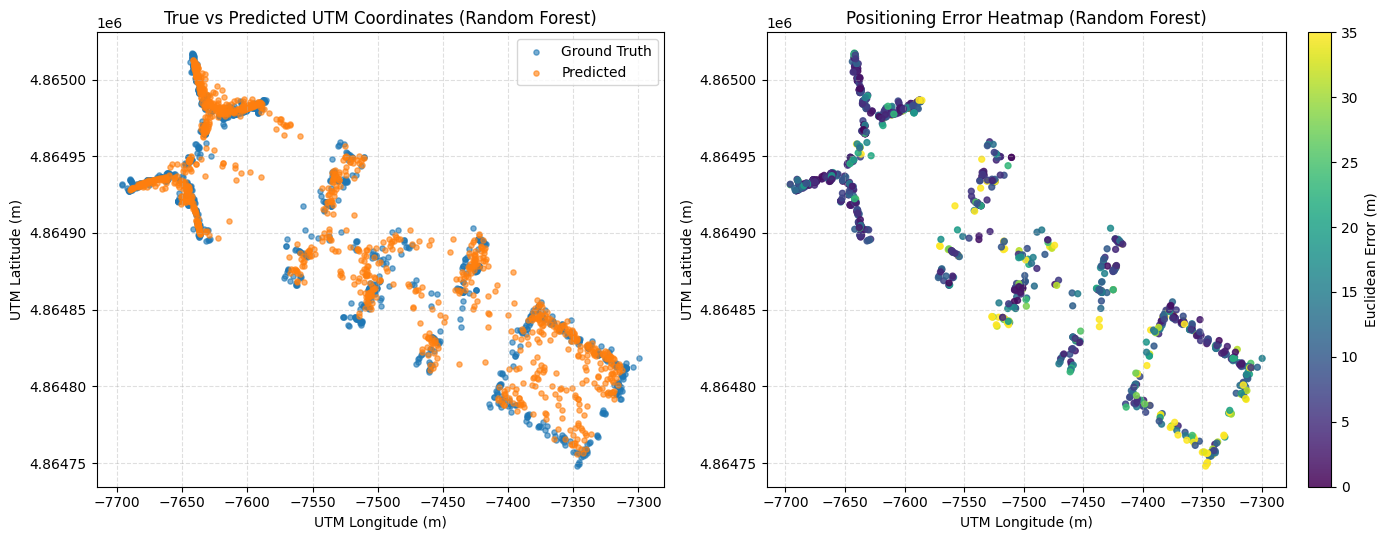

Top Coordinate Model: Random Forest
  Mean Euclidean Error:   12.30 m
  Median Euclidean Error: 8.15 m
  90th Percentile Error:  29.55 m


In [14]:
error_df = pd.DataFrame({
    model_name: errors for model_name, errors in prediction_errors.items()
})

# 1. Error Distribution Boxplot
plt.figure(figsize=(9, 4.5))
plt.boxplot(
    [error_df[c].values for c in error_df.columns],
    tick_labels=error_df.columns,
    showfliers=False
)
plt.ylabel("Euclidean Positioning Error (meters)")
plt.title("Positioning Error Distribution across Models (Outliers Suppressed for Readability)")
plt.xticks(rotation=15, ha="right")
plt.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()

# 2. Spatial Mapping of Predictions
best_model_name = regression_results.iloc[0]["model"]
best_xy = predictions[best_model_name]["coordinates"]
true_xy = y_val[REGRESSION_TARGETS].to_numpy(dtype=float)
best_err = prediction_errors[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(true_xy[:, 0], true_xy[:, 1], c="tab:blue", s=14, alpha=0.6, label="Ground Truth")
axes[0].scatter(best_xy[:, 0], best_xy[:, 1], c="tab:orange", s=14, alpha=0.6, label="Predicted")
axes[0].set_title(f"True vs Predicted UTM Coordinates ({best_model_name})")
axes[0].set_xlabel("UTM Longitude (m)")
axes[0].set_ylabel("UTM Latitude (m)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

sc = axes[1].scatter(true_xy[:, 0], true_xy[:, 1], c=best_err, cmap="viridis", s=18, alpha=0.85, vmin=0, vmax=35)
axes[1].set_title(f"Positioning Error Heatmap ({best_model_name})")
axes[1].set_xlabel("UTM Longitude (m)")
axes[1].set_ylabel("UTM Latitude (m)")
axes[1].grid(True, linestyle="--", alpha=0.4)
cbar = fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label("Euclidean Error (m)")

plt.tight_layout()
plt.show()

print(f"Top Coordinate Model: {best_model_name}")
print(f"  Mean Euclidean Error:   {np.mean(best_err):.2f} m")
print(f"  Median Euclidean Error: {np.median(best_err):.2f} m")
print(f"  90th Percentile Error:  {np.percentile(best_err, 90):.2f} m")


## 15. Performance by Building Disaggregation

Aggregated performance metrics often obscure building-specific variations caused by distinct building geometries, construction materials, and AP densities. We disaggregate performance by building.


In [15]:
bldg_rows = []
for model_name, pred in predictions.items():
    for building in sorted(y_val["BUILDINGID"].unique()):
        mask = y_val["BUILDINGID"].to_numpy() == building
        xy_true = y_val.loc[mask, REGRESSION_TARGETS].to_numpy(dtype=float)
        xy_pred = np.asarray(pred["coordinates"])[mask]
        err = position_errors(xy_true, xy_pred)
        
        bldg_rows.append({
            "model": model_name,
            "building_id": int(building),
            "test_samples": int(mask.sum()),
            "building_accuracy": accuracy_score(y_val.loc[mask, "BUILDINGID"], pred["BUILDINGID"][mask]),
            "floor_accuracy": accuracy_score(y_val.loc[mask, "FLOOR"], pred["FLOOR"][mask]),
            "mean_error_m": float(np.mean(err)),
            "median_error_m": float(np.median(err))
        })

by_building_results = pd.DataFrame(bldg_rows)
print("--- Breakdown of Performance by True Building ---")
display(by_building_results[by_building_results["model"].isin(["Random Forest", "KNN (k=5, distance-weighted)", "XGBoost"])].round(3))


--- Breakdown of Performance by True Building ---


,model,building_id,test_samples,building_accuracy,floor_accuracy,mean_error_m,median_error_m
3,Random Forest,0,536,0.998,0.968,8.484,5.313
4,Random Forest,1,307,0.993,0.805,14.469,10.119
5,Random Forest,2,268,1.000,0.869,17.456,11.556
9,"KNN (k=5, distance-weighted)",0,536,0.989,0.759,12.846,6.714
10,"KNN (k=5, distance-weighted)",1,307,0.980,0.710,13.068,9.148
11,"KNN (k=5, distance-weighted)",2,268,1.000,0.795,16.033,9.975
12,XGBoost,0,536,0.996,0.946,21.232,11.202
13,XGBoost,1,307,1.000,0.782,20.545,17.835
14,XGBoost,2,268,1.000,0.925,28.113,19.239


## 16. Task 10: Feature Importance and Model Interpretability

Using the Mean Decrease in Impurity (MDI / Gini Importance) from Random Forest:
- We identify the top 20 access points driving building and floor discrimination.
- We observe how both raw signal strength features (`WAPxxx`) and detection indicators contribute to spatial splits.


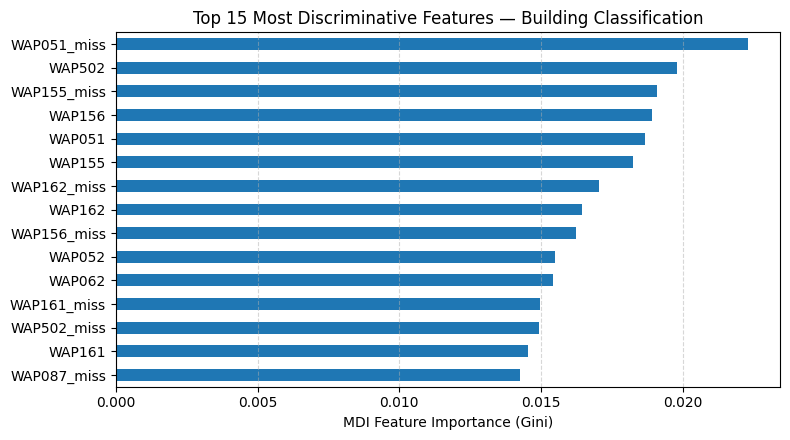

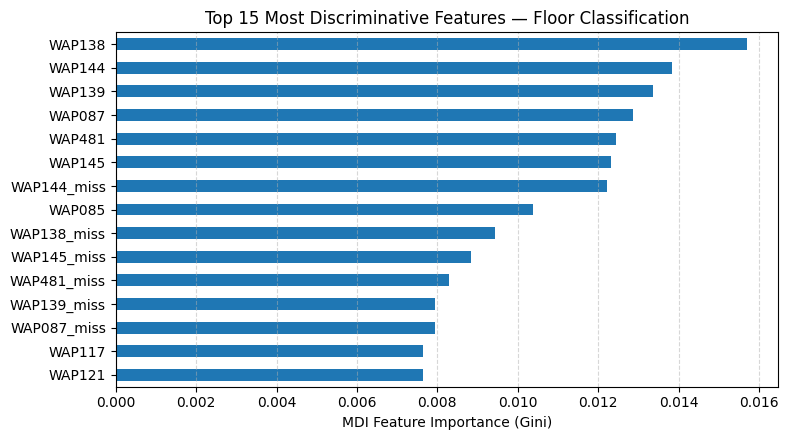

,Top Building Features,Building Importance,Top Floor Features,Floor Importance
0,WAP051_miss,0.0223,WAP138,0.0157
1,WAP502,0.0198,WAP144,0.0138
2,WAP155_miss,0.0191,WAP139,0.0134
3,WAP156,0.0189,WAP087,0.0129
4,WAP051,0.0187,WAP481,0.0124
5,WAP155,0.0183,WAP145,0.0123
6,WAP162_miss,0.0171,WAP144_miss,0.0122
7,WAP162,0.0164,WAP085,0.0104
8,WAP156_miss,0.0162,WAP138_miss,0.0094
9,WAP052,0.0155,WAP145_miss,0.0088


In [16]:
def plot_top_importances(model, feature_names, title, top_n=15):
    imp = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False).head(top_n)
    imp_sorted = imp.sort_values(ascending=True)
    plt.figure(figsize=(8, 4.5))
    imp_sorted.plot(kind="barh", color="#1f77b4")
    plt.xlabel("MDI Feature Importance (Gini)")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5, axis="x")
    plt.tight_layout()
    plt.show()
    return imp

building_importance = plot_top_importances(
    rf_building, X_train_df.columns, "Top 15 Most Discriminative Features — Building Classification"
)
floor_importance = plot_top_importances(
    rf_floor, X_train_df.columns, "Top 15 Most Discriminative Features — Floor Classification"
)

display(pd.DataFrame({
    "Top Building Features": building_importance.index[:15],
    "Building Importance": building_importance.values[:15],
    "Top Floor Features": floor_importance.index[:15],
    "Floor Importance": floor_importance.values[:15]
}).round(4))


## 17. Task 8: Artifact Persistence and Metrics Export

Export all generated metrics, hyperparameter tuning tables, validation predictions, and model run metadata to `results/metrics/` and `report/model_evaluation/`.


In [17]:
# Define output directories
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
REPORTS_DIR = PROJECT_ROOT / "report" / "model_evaluation"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

for d in [METRICS_DIR, REPORTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 1. Export tables
master_table.to_csv(METRICS_DIR / "classical_ml_summary.csv", index=False)
classification_results.to_csv(METRICS_DIR / "classification_results.csv", index=False)
regression_results.to_csv(METRICS_DIR / "coordinate_regression_results.csv", index=False)
by_building_results.to_csv(METRICS_DIR / "results_by_building.csv", index=False)
knn_tuning_df.to_csv(METRICS_DIR / "knn_hyperparameter_tuning.csv", index=False)
rf_tuning_df.to_csv(METRICS_DIR / "rf_hyperparameter_tuning.csv", index=False)
user_cv_df.to_csv(METRICS_DIR / "user_grouped_cv_results.csv", index=False)

# Sync with reports directory
master_table.to_csv(REPORTS_DIR / "master_model_comparison.csv", index=False)
classification_results.to_csv(REPORTS_DIR / "classification_results.csv", index=False)
regression_results.to_csv(REPORTS_DIR / "coordinate_regression_results.csv", index=False)

# 2. Export detailed predictions
prediction_output = y_val.reset_index(drop=True).copy()
for model_name, pred in predictions.items():
    safe_name = model_name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("=", "").replace("-", "_").replace(",", "")
    prediction_output[f"{safe_name}_building_pred"] = pred["BUILDINGID"]
    prediction_output[f"{safe_name}_floor_pred"] = pred["FLOOR"]
    prediction_output[f"{safe_name}_lon_pred"] = np.asarray(pred["coordinates"])[:, 0]
    prediction_output[f"{safe_name}_lat_pred"] = np.asarray(pred["coordinates"])[:, 1]
    prediction_output[f"{safe_name}_position_error"] = prediction_errors[model_name]

prediction_output.to_csv(METRICS_DIR / "validation_predictions.csv", index=False)
prediction_output.to_csv(REPORTS_DIR / "validation_predictions.csv", index=False)

# 3. Export feature importances
building_importance.rename("importance").to_csv(METRICS_DIR / "rf_building_feature_importance.csv")
floor_importance.rename("importance").to_csv(METRICS_DIR / "rf_floor_feature_importance.csv")

# 4. Export run metadata
run_info = {
    "random_seed": SEED,
    "train_rows_raw": int(len(train_df)),
    "train_rows_cleaned": int(X_train.shape[0]),  # after dedup + empty-scan removal in prepare_features
    "validation_rows": int(len(val_df)),
    "n_features": int(X_train.shape[1]),
    "preprocessing_config": MODEL_FEATURE_CONFIG,
    "xgboost_available": bool(XGBOOST_AVAILABLE),
    "evaluated_models": list(predictions.keys()),
    "best_regression_model": str(regression_results.iloc[0]["model"]),
    "best_mean_error_m": float(regression_results.iloc[0]["mean_position_error"]),
    "best_median_error_m": float(regression_results.iloc[0]["median_position_error"])
}
with open(METRICS_DIR / "classical_ml_run_info.json", "w", encoding="utf-8") as f:
    json.dump(run_info, f, indent=2)

print("Export completed successfully:")
print("  Metrics directory:", METRICS_DIR.resolve())
print("  Reports directory:", REPORTS_DIR.resolve())


Export completed successfully:
  Metrics directory: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/metrics
  Reports directory: /Users/soumyatiwari/Desktop/indoor-wifi-positioning/report/model_evaluation
